# Setup

In [1]:
!pip install torch opencv-python numpy torchvision Pillow -q

In [10]:
import os

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import random
import numpy as np
import matplotlib.pyplot as plt

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [4]:
# fix seed để reproduce
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Ép cuDNN dùng thuật toán xác định (deterministic)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# Dataset

In [5]:
DATA_ROOT = "/kaggle/input/datasets/tuanannguyen/garbage-classification"

## Preprocess ảnh

In [6]:
IMAGE_SIZE = 64

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), 
    
    # data augmentation
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(45),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),

    transforms.ToTensor(), # cho về tensor và norm [0,1]
    transforms.Normalize(  # norm về [-1,1] để phân bố đều hơn
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])

### Tạo Dataset

Đọc cái thư mục ảnh và áp cái transform vào

In [7]:
train_ds = datasets.ImageFolder(
    root=os.path.join(DATA_ROOT, "train"),
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    root=os.path.join(DATA_ROOT, "val"),
    transform=val_transform
)

test_ds = datasets.ImageFolder(
    root=os.path.join(DATA_ROOT, "test"),
    transform=val_transform
)

In [8]:
print(train_ds.classes)
print(train_ds.class_to_idx)

print(train_ds)

['cardboard', 'glass', 'metal', 'paper', 'plastic']
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4}
Dataset ImageFolder
    Number of datapoints: 1910
    Root location: /kaggle/input/datasets/tuanannguyen/garbage-classification/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-45.0, 45.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
               ToTensor()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )


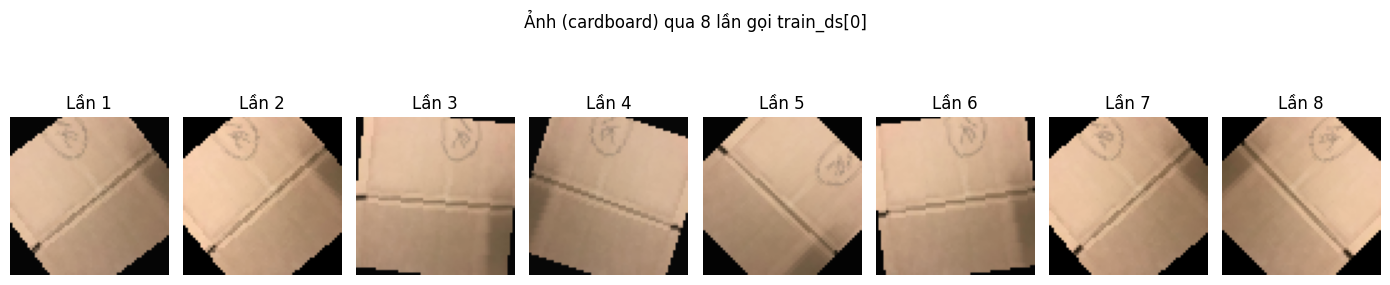

In [11]:
def show_augmented_samples(dataset, idx=0, n_samples=8):
    plt.figure(figsize=(14, 3.5))
    for i in range(n_samples):
        img, label = dataset[idx]  # Lấy đi lấy lại đúng 1 ảnh ở vị trí idx

        # Unnormalize từ [-1, 1] về [0, 1] và đổi chiều [C, H, W] -> [H, W, C]
        img = (img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(1, n_samples, i + 1)
        plt.imshow(img)
        plt.title(f"Lần {i + 1}")
        plt.axis("off")

    plt.suptitle(f"Ảnh ({dataset.classes[label]}) qua {n_samples} lần gọi train_ds[{idx}]")
    plt.tight_layout()
    plt.show()

show_augmented_samples(train_ds, idx=0, n_samples=8)

### Dataloader

Load data theo batch

In [12]:
BATCH_SIZE = 64

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(42)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=True,
    worker_init_fn=seed_worker, # để reproduce
    generator=g # để reproduce
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

In [13]:
X_batch, y_batch = next(iter(train_loader))

print(X_batch.shape)  # [32, 3, 64, 64]
print(y_batch.shape)  # [32]

torch.Size([64, 3, 64, 64])
torch.Size([64])


# CNN

In [14]:
class MyCNN(nn.Module):
    """
    Conv1 -> pool -> conv2 -> pool 
    -> <flatten> 
    -> FC1 -> FC2 -> FC3
    
    inputSize = 64 * 64 * 3

    activation là ReLU
    """
    def __init__(self, num_classes=5):
        super().__init__()

        # Tính size sau khi conv: (input - kernel + 2*padding) / stride + 1

        self.features = nn.Sequential(
            # Conv1 -> pool -> conv2 -> pool 

            # input là 3 màu RGB, 16 filter size 3x3 
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3),  # [16, 62, 62]
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # quét kernel 2x2 lấy max trong 4 giá trị, [16, 31, 31]

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5), # [32, 27, 27]
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # [32, 13, 13]
        )

        # <flatten trước khi vào FC>

        self.classifier = nn.Sequential(
            # FC1 -> FC2 -> FC3

            nn.Linear(in_features=32 * 13 * 13, out_features=128),
            nn.ReLU(),

            nn.Linear(in_features=128, out_features=64),
            nn.ReLU(),

            nn.Linear(in_features=64, out_features=num_classes),
        )

    def forward(self, x):
        # Conv1 -> pool -> conv2 -> pool 
        x = self.features(x)

        # flatten từ 2d thành 1d 
        x = torch.flatten(input=x, start_dim=1)

        # FC1 -> FC2 -> FC3
        x = self.classifier(x)
        return x

In [15]:
num_classes = 5

mycnn = MyCNN(num_classes=num_classes).to(device)

## Loss, optimizer

In [16]:
# patience cho early stop: sau 15 lần val acc ko tăng -> dừng
patience = 15

loss_function = nn.CrossEntropyLoss()

optimizer = optim.SGD(mycnn.parameters(), lr=0.01, momentum=0.9)

# giảm lr nếu val_loss (patience phải nhỏ hơn patience early stop)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)

## Training loop

Train và save weights

In [17]:
epochs = 100
best_val_acc = 0.0

# dừng sớm nếu val_acc ko tăng
no_improve_count = 0

# để vẽ learning curve
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

# đưa model về train mode
mycnn.train()
for epoch in range(epochs):
    train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    # train trên từng batch
    for data in train_loader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # reset optimizer gradient
        optimizer.zero_grad()
        outputs = mycnn(inputs)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        # Tính accuracy train
        _, predicted = torch.max(outputs, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # valdidation loop
    mycnn.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for data in val_loader:
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = mycnn(inputs)
            
            loss = loss_function(outputs, labels)
            val_loss += loss.item()
            
            _, predicted = torch.max(outputs, dim=1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()


    mycnn.train() # Chuyển lại về train mode cho epoch sau


    train_loss_avg = train_loss / len(train_loader)
    val_loss_avg = val_loss / len(val_loader)

    train_acc = 100 * correct_train / total_train
    val_acc = 100 * correct_val / total_val

    
    # Lưu lại lịch sử để vẽ đồ thị
    history["train_loss"].append(train_loss_avg)
    history["val_loss"].append(val_loss_avg)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    

    print(f"Epoch {epoch:02d} | Train Loss: {train_loss_avg:.4f} | Val Loss: {val_loss_avg:.4f} | "
        f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")


    scheduler.step(val_loss_avg)


    # Lưu model tốt nhất
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(mycnn.state_dict(), "best_mycnn.pth")
        no_improve_count = 0
    else:
        no_improve_count += 1
    
    if no_improve_count >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

print(f"\nTraining Finished. Best Val Acc: {best_val_acc:.2f}%")

Epoch 00 | Train Loss: 1.6102 | Val Loss: 1.5966 | Train Acc: 22.88% | Val Acc: 24.79%
Epoch 01 | Train Loss: 1.5733 | Val Loss: 1.5473 | Train Acc: 24.50% | Val Acc: 26.05%
Epoch 02 | Train Loss: 1.4421 | Val Loss: 1.4097 | Train Acc: 35.92% | Val Acc: 36.13%
Epoch 03 | Train Loss: 1.3528 | Val Loss: 1.3571 | Train Acc: 42.51% | Val Acc: 40.34%
Epoch 04 | Train Loss: 1.3009 | Val Loss: 1.3395 | Train Acc: 44.82% | Val Acc: 47.48%
Epoch 05 | Train Loss: 1.2604 | Val Loss: 1.2484 | Train Acc: 48.95% | Val Acc: 44.54%
Epoch 06 | Train Loss: 1.2253 | Val Loss: 1.2218 | Train Acc: 49.63% | Val Acc: 46.22%
Epoch 07 | Train Loss: 1.1878 | Val Loss: 1.1643 | Train Acc: 52.77% | Val Acc: 52.94%
Epoch 08 | Train Loss: 1.1953 | Val Loss: 1.2550 | Train Acc: 52.04% | Val Acc: 47.06%
Epoch 09 | Train Loss: 1.1191 | Val Loss: 1.1043 | Train Acc: 57.23% | Val Acc: 55.88%
Epoch 10 | Train Loss: 1.0898 | Val Loss: 1.0718 | Train Acc: 56.91% | Val Acc: 52.10%
Epoch 11 | Train Loss: 1.0698 | Val Loss: 1

### Plot learning curve

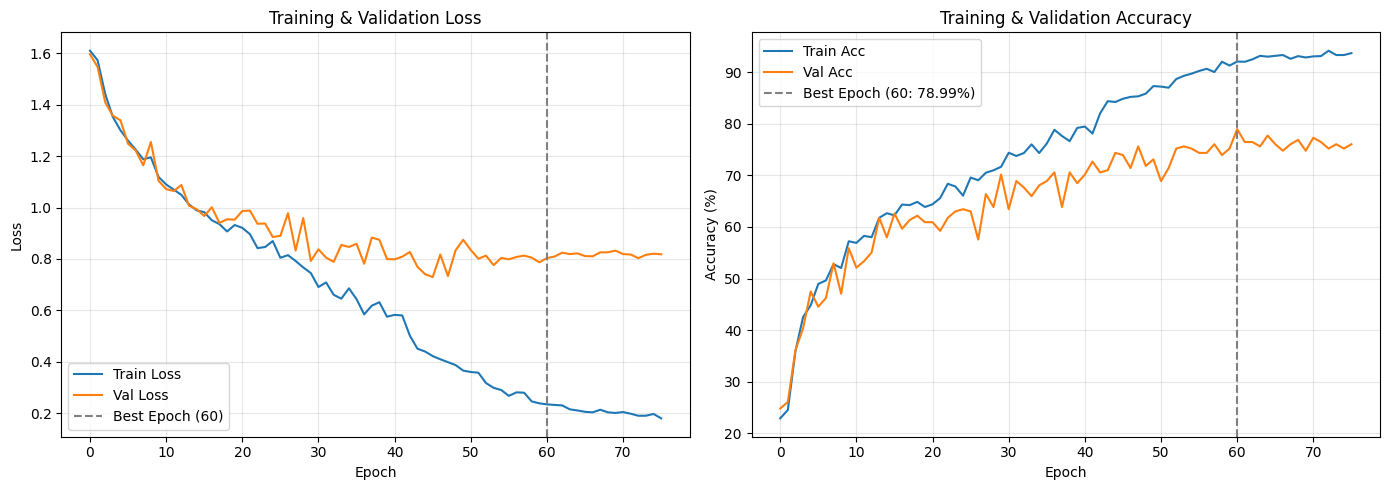

In [18]:
import matplotlib.pyplot as plt

epochs_range = range(len(history["train_loss"]))
best_epoch = int(np.argmax(history["val_acc"]))
best_acc = history["val_acc"][best_epoch]


plt.figure(figsize=(14, 5))

# 1. Biểu đồ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Val Loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best Epoch ({best_epoch})")
plt.title("Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Biểu đồ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], label="Train Acc")
plt.plot(epochs_range, history["val_acc"], label="Val Acc")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best Epoch ({best_epoch}: {best_val_acc:.2f}%)")
plt.title("Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Evaluation

### Load weights

In [19]:
mycnn = MyCNN(num_classes=num_classes).to(device)

mycnn.load_state_dict(torch.load("best_mycnn.pth", map_location=device))

<All keys matched successfully>

### Eval

In [20]:
# chuyển model về evaluation mode
mycnn.eval()

total = 0 # là tổng số test data
correct = 0 # số data predict đúng (có output == label)

with torch.no_grad():
    # bóc batch test ra eval
    for data in test_loader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = mycnn(inputs)
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


accuracy = (correct / total) * 100
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 76.03


### Class-wise Metrics & Confusion Matrix

Accuracy: 76.03%

Class-wise metrics

              precision    recall  f1-score   support

   cardboard     0.8919    0.8049    0.8462        41
       glass     0.7222    0.7647    0.7429        51
       metal     0.7714    0.6585    0.7105        41
       paper     0.7606    0.9000    0.8244        60
     plastic     0.6889    0.6327    0.6596        49

    accuracy                         0.7603       242
   macro avg     0.7670    0.7522    0.7567       242
weighted avg     0.7621    0.7603    0.7582       242



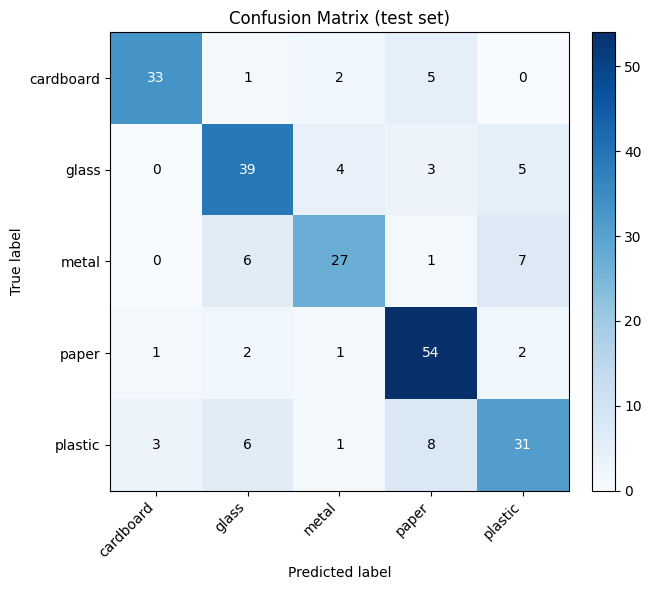

In [26]:
# ===== Class-wise metrics (Precision / Recall / F1) & Confusion Matrix =====
from sklearn.metrics import classification_report, confusion_matrix

mycnn.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = mycnn(inputs)
        _, predicted = torch.max(outputs, dim=1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

class_names = test_ds.classes  # tên lớp theo đúng thứ tự index

# --- Accuracy tổng thể ---
accuracy = (all_preds == all_labels).mean() * 100
print(f"Accuracy: {accuracy:.2f}%\n")

# --- Precision / Recall / F1 cho từng lớp ---
report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print("Class-wise metrics\n")
print(report)

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")

ax.set_title("Confusion Matrix (test set)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)

# ghi giá trị số lên từng ô
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black",
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Load image

In [22]:
def load_image_from_path(image_path):
    """
    Hàm để đưa ảnh vào model (do ảnh có thể ở bất kì size nào -> format lại)
    """
    # đọc ảnh
    image = Image.open(image_path).convert("RGB")

    # format (resize, normalize...)
    image = val_transform(image)

    # biến cái hình thành batch 1 ảnh (thêm 1 chiều ở đầu, do model input kiểu ntn)
    # VD: [12,12,3] -> [1,12,12,3] 
    image = image.unsqueeze(0)

    return image

In [23]:
@torch.no_grad()
def classify_1_image(image_path, model):
    model.eval()

    image = load_image_from_path(image_path).to(device)

    output = model(image) # shape: [1, 5] (giá trị thô)

    # xác suất từng class
    probs = torch.softmax(output, dim=1).squeeze(0) # shape [5] 
    
    # Tạo dictionary {tên_class: xác_suất_%} và sắp xếp giảm dần
    result = {
        class_name: round(prob.item(), 4)
        for class_name, prob in zip(train_ds.classes, probs)
    }
    sorted_result = dict(sorted(result.items(), key=lambda item: item[1], reverse=True))

    # class với prob lớn nhất
    top_class = next(iter(sorted_result))

    return top_class, sorted_result

In [24]:
mycnn.eval()

test_image_path = "/kaggle/input/datasets/tuanannguyen/garbage-classification/test/metal/metal101.jpg"
test_class, probs = classify_1_image(test_image_path, mycnn)

print(test_class)
print(probs)

metal
{'metal': 0.9989, 'cardboard': 0.0009, 'plastic': 0.0002, 'glass': 0.0, 'paper': 0.0}
